In [24]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from urllib.parse import quote_plus
from sqlalchemy import create_engine
from dotenv import load_dotenv

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, RocCurveDisplay)
from xgboost import XGBClassifier

load_dotenv()
engine = create_engine(
    f"mysql+pymysql://{os.getenv('MYSQL_USER')}:{quote_plus(os.getenv('MYSQL_PASSWORD'))}"
    f"@{os.getenv('MYSQL_HOST')}/{os.getenv('MYSQL_DB')}"
)
df = pd.read_sql("SELECT * FROM customers_features", engine)
print(df.shape)


(7043, 32)


In [25]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())  

(5634, 30) (1409, 30)
0.2653532126375577 0.2654364797728886


In [26]:
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)
log_model.fit(X_train, y_train)

log_pred = log_model.predict(X_test)
log_proba = log_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, log_pred))
print("ROC-AUC:", round(roc_auc_score(y_test, log_proba), 3))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.842


In [27]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=neg / pos,
    eval_metric="logloss",
    random_state=42
)
xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, xgb_pred))
print("ROC-AUC:", round(roc_auc_score(y_test, xgb_proba), 3))

              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.52      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409

ROC-AUC: 0.841


                 model  ROC-AUC
0  Logistic Regression    0.842
1              XGBoost    0.841


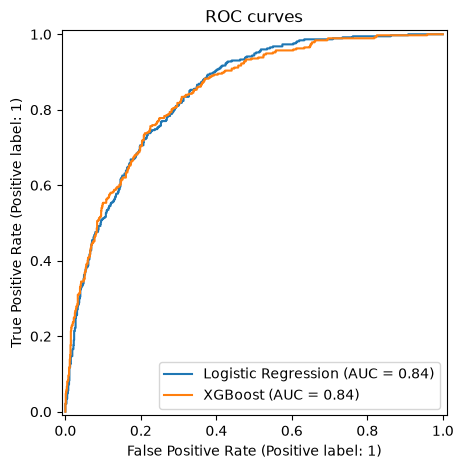

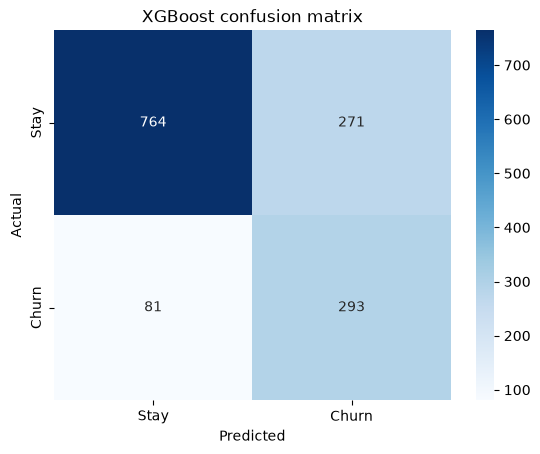

In [28]:
results = pd.DataFrame({
    "model": ["Logistic Regression", "XGBoost"],
    "ROC-AUC": [roc_auc_score(y_test, log_proba), roc_auc_score(y_test, xgb_proba)]
}).round(3)
print(results)

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, log_proba, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, xgb_proba, name="XGBoost", ax=ax)
plt.title("ROC curves")
plt.show()

sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost confusion matrix")
plt.show()

In [29]:
os.makedirs("../models", exist_ok=True)
joblib.dump(log_model, "../models/logistic_model.pkl")
joblib.dump(xgb_model, "../models/xgb_model.pkl")
joblib.dump(list(X.columns), "../models/feature_columns.pkl")

['../models/feature_columns.pkl']

In [30]:
os.makedirs("../models", exist_ok=True)
joblib.dump(log_model, "../models/logistic_model.pkl")
joblib.dump(xgb_model, "../models/xgb_model.pkl")
joblib.dump(list(X.columns), "../models/feature_columns.pkl")

['../models/feature_columns.pkl']